<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and recorded source](README.md)

# 01 · Front-page rank and score describe different orderings

Is the Hacker News front page simply sorted by score? We will freeze one bounded ranking sample, distinguish eligible stories from jobs and unavailable values, and count pairs whose rank order disagrees with descending score. Item age adds context; it does not reveal the ranking algorithm.

**Default: recorded public Hacker News API responses.** A complete ranking-ID response and all corresponding complete item responses are replayed through the real worker. The ranking was acquired before item hydration, so ranks, scores and timestamps are not an atomic snapshot. This describes one sampled list, not story quality, vote velocity or the performance of authors.

## Select a prefix of the same materialized ranking

`TOP_N` accepts **30** (default) or **100** (experiment), using the API's 1-based rank. Retrieval always materializes the complete API-bounded top list (at most 500 IDs) before this local rank filter. Change **30 → 100** to widen the population; predict more comparable pairs, but not a particular direction for their disagreement fraction.

`DATA_MODE="live"` reads a new public ranking; it never falls back to recordings. Restart Kernel → Run All after editing. Replay keeps the source fingerprint fixed between experiments.

In [1]:
TOP_N = 30  # Accepted: 30 or 100 API ranks; experiment: 100
DATA_MODE = "replay"  # "replay" or "live"; no fallback

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from replay_source import ReplaySource

assert type(TOP_N) is int and TOP_N in {30, 100}
assert DATA_MODE in {"replay", "live"}
manifest = json.loads(Path("fixtures/manifest.json").read_text())
previous_base = os.environ.get("HN_BASE_URL")
server = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
os.environ["HN_BASE_URL"] = server.url if server else "https://hacker-news.firebaseio.com/v0"
started_at = datetime.now(UTC).isoformat()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Source: {DATA_MODE.upper()} Hacker News API · acquisition ended {AS_OF[:19]} UTC · selected API ranks 1–{TOP_N} · non-atomic snapshot",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.07, 1, 0.97))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-hackernews/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-hackernews/notebooks/pyproject.toml.

## Use the pinned public worker and materialize the bounded source

The literal Git tag resolves to `831a83838db94f91cb3e064b6ea900ef753c10bb`; `uvx` installs its tested runtime independently of this checkout. `HN_BASE_URL` is the worker's documented mirror/test endpoint setting. Replay uses a strict hash-checked loopback server; live explicitly uses the official public endpoint.

The [official API](https://github.com/HackerNews/API) supplies at most 500 top-story IDs, then one response per item. This worker hydrates 100 IDs per batch. We materialize the complete bounded list once, then select rank prefixes locally. **A returned-row LIMIT does not establish a network-request bound**: the tested SQL runtime can begin hydrating an additional batch before cancellation. This notebook uses the API's finite list as its retrieval boundary and applies no SQL LIMIT to that retrieval.

The recording has one complete 500-ID response and one complete response for each ID. The first 100 and remaining 400 items were acquired in separate batches; individual UTC timestamps are preserved. Replay rejects every unrecorded path and has no fallback.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'hackernews' AS hn (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-hackernews@v0.3.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx2==2.13.0 --with pyarrow==25.0.1 vgi-hackernews'
);

,Success


In [4]:
%%sql
CREATE TABLE ranking AS
SELECT rank,id,type,score,created_at,deleted,dead
FROM hn.main.top_stories;

,Count


In [5]:
AS_OF = manifest["capture_completed_at_utc"] if server else datetime.now(UTC).isoformat()
source = con.execute("SELECT * FROM ranking ORDER BY rank").df()
fingerprint = hashlib.sha256(source.to_json(orient="records", date_format="iso").encode()).hexdigest()
assert 0 < len(source) <= 500 and source.id.is_unique and source["rank"].is_unique
assert source["rank"].between(1, 500).all()
if server:
    feed = json.loads(Path("fixtures/topstories.json").read_bytes())
    assert source.id.tolist() == feed
    assert source["rank"].tolist() == list(range(1, len(feed) + 1))
    assert set(server.requests) == {"/v0/topstories.json"} | {f"/v0/item/{i}.json" for i in feed}
    assert len(server.requests) == len(feed) + 1
    display(
        pd.DataFrame([{"requested_path": x} for x in server.requests]).assign(
            request_number=lambda x: range(1, len(x) + 1)
        )
    )
prose(
    f"**{DATA_MODE.upper()} · {len(source)} unique items materialized**, covering returned ranks **{int(source['rank'].min())}–{int(source['rank'].max())}**. Acquisition completion `{AS_OF}` is the age reference clock, not an atomic observation time. Returned-source fingerprint: `{fingerprint}`. All remaining SQL uses this local table."
)
if server:
    prose(
        f"Replay request audit: **{len(server.requests)} requests, {len(set(server.requests))} distinct paths**, covering exactly the recorded list and its items. No replay misses occurred."
    )
audit_path = Path("artifacts/request-audit.json")
audit_path.parent.mkdir(exist_ok=True)
audit_path.write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "requested_paths": server.requests if server else None,
            "note": "Exact local replay trace; live network is not instrumented",
        },
        indent=2,
    )
    + "\n"
)

,requested_path,request_number
0,/v0/topstories.json,1
1,/v0/item/50489641.json,2
2,/v0/item/50493062.json,3
3,/v0/item/50491423.json,4
4,/v0/item/50493251.json,5
...,...,...
496,/v0/item/50481227.json,497
497,/v0/item/50472323.json,498
498,/v0/item/50453513.json,499
499,/v0/item/50473671.json,500


**REPLAY · 500 unique items materialized**, covering returned ranks **1–500**. Acquisition completion `2026-11-14T07:21:47.660719+00:00` is the age reference clock, not an atomic observation time. Returned-source fingerprint: `6766c4158b114b5caaa7740f20578786b87a154a2207fe665072da778a8f7530`. All remaining SQL uses this local table.

Replay request audit: **501 requests, 501 distinct paths**, covering exactly the recorded list and its items. No replay misses occurred.

15149

## Define which rows can enter a score comparison

The selected prefix includes every returned item with `rank <= TOP_N`. We retain diagnostics for non-story items, deleted/dead items and missing or invalid scores. Only a live story with a known nonnegative score enters the pair comparison; score zero remains a real value.

Age is hours since the item's UTC creation timestamp to acquisition completion. Missing or future timestamps produce an unavailable age; they do not exclude an otherwise eligible score. Scores are API scores, not a count of votes observed during a fixed interval.

In [6]:
%%sql
CREATE TABLE classified AS
SELECT *,CASE
 WHEN type IS DISTINCT FROM 'story' THEN 'Non-story item'
 WHEN deleted OR dead THEN 'Deleted or dead story'
 WHEN score IS NULL OR score<0 THEN 'Unavailable score'
 ELSE 'Eligible story' END AS eligibility,
 CASE WHEN created_at<=TIMESTAMPTZ '{{AS_OF}}'
      THEN epoch(TIMESTAMPTZ '{{AS_OF}}'-created_at)/3600.0 END AS age_hours
FROM ranking;
CREATE TABLE selected AS SELECT * FROM classified WHERE rank<={{TOP_N}};
CREATE TABLE eligible AS SELECT * FROM selected WHERE eligibility='Eligible story';

,Count


In [7]:
%%sql coverage <<
SELECT eligibility,count(*) AS items,
 count(*) FILTER (WHERE age_hours IS NULL) AS unavailable_age
FROM selected GROUP BY eligibility ORDER BY eligibility;

In [8]:
display(coverage)
eligible_rows = con.execute("SELECT * FROM eligible ORDER BY rank").df()
assert coverage["items"].sum() == con.execute("SELECT count(*) FROM selected").fetchone()[0]
assert len(eligible_rows) >= 2
assert eligible_rows.score.notna().all() and eligible_rows.score.ge(0).all()
assert eligible_rows.age_hours.dropna().ge(0).all()
prose(
    f"Among **{int(coverage['items'].sum())} selected items**, **{len(eligible_rows)} stories** have comparable scores. Their observed ages are context for the snapshot; dividing scores by age would not establish a voting rate, because no vote-time series was fetched."
)

,eligibility,items,unavailable_age
0,Eligible story,29,0
1,Non-story item,1,0


Among **30 selected items**, **29 stories** have comparable scores. Their observed ages are context for the snapshot; dividing scores by age would not establish a voting rate, because no vote-time series was fetched.

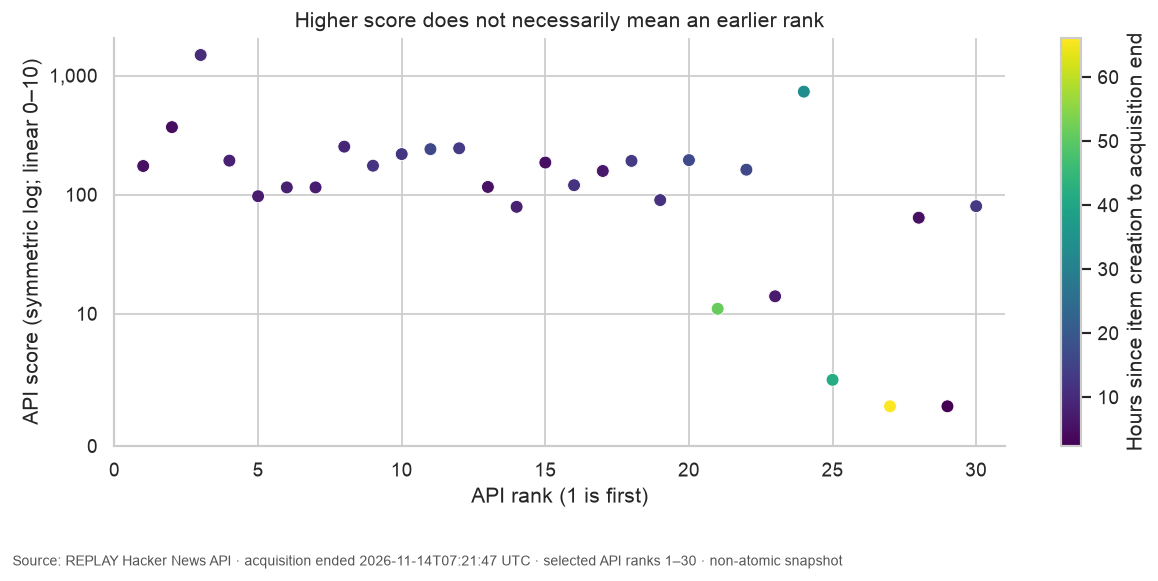

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
known = eligible_rows[eligible_rows.age_hours.notna()]
unknown = eligible_rows[eligible_rows.age_hours.isna()]
if len(known):
    points = ax.scatter(
        known["rank"], known.score, c=known.age_hours, cmap="viridis", s=55, edgecolors="white", linewidth=0.5
    )
    fig.colorbar(points, ax=ax, label="Hours since item creation to acquisition end")
if len(unknown):
    ax.scatter(unknown["rank"], unknown.score, marker="x", color="#777777", label="Age unavailable")
    ax.legend()
ax.set_yscale("symlog", linthresh=10)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.set(
    xlabel="API rank (1 is first)",
    ylabel="API score (symmetric log; linear 0–10)",
    title="Higher score does not necessarily mean an earlier rank",
    xlim=(0, TOP_N + 1),
    ylim=(0, max(10, eligible_rows.score.max() * 1.4)),
)
finish(fig)

## Count order disagreements with an explicit pair denominator

Consider each unordered pair once by requiring `a.rank < b.rank`. It disagrees with descending score when the earlier-ranked story has a lower score. Equal-score pairs cannot distinguish the score ordering, so report them separately and exclude them from the disagreement fraction.

This is a descriptive statistic for this selected list. It does not estimate an algorithm, test a causal explanation, or attach uncertainty to an unobserved population.

In [10]:
%%sql pairs <<
SELECT count(*) AS all_pairs,
 count(*) FILTER (WHERE a.score=b.score) AS tied_score_pairs,
 count(*) FILTER (WHERE a.score<>b.score) AS comparable_pairs,
 count(*) FILTER (WHERE a.score<b.score) AS disagreements,
 count(*) FILTER (WHERE a.score<b.score)*1.0/
   nullif(count(*) FILTER (WHERE a.score<>b.score),0) AS disagreement_fraction
FROM eligible a JOIN eligible b ON a.rank<b.rank;

In [11]:
display(pairs)
r = pairs.iloc[0]
assert r.all_pairs == len(eligible_rows) * (len(eligible_rows) - 1) // 2
assert r.tied_score_pairs + r.comparable_pairs == r.all_pairs
assert 0 <= r.disagreements <= r.comparable_pairs
fraction = (
    "unavailable (all scores tied)" if pd.isna(r.disagreement_fraction) else f"{r.disagreement_fraction:.1%}"
)
prose(
    f"Of **{int(r.all_pairs):,} story pairs**, **{int(r.tied_score_pairs):,} tie on score**. Among the **{int(r.comparable_pairs):,} comparable pairs**, **{int(r.disagreements):,} ({fraction})** put a lower-score story earlier. This establishes that score order and observed rank order differ in this sample; it does not identify why."
)

,all_pairs,tied_score_pairs,comparable_pairs,disagreements,disagreement_fraction
0,406,2,404,124,0.306931


Of **406 story pairs**, **2 tie on score**. Among the **404 comparable pairs**, **124 (30.7%)** put a lower-score story earlier. This establishes that score order and observed rank order differ in this sample; it does not identify why.

## Inspect the highest scores within the same selected population

These are the eight highest-scoring eligible stories **within the selected rank prefix**, not the highest-scoring stories site-wide. Score ties use ascending API rank. Item IDs provide stable references without copying story text. The horizontal axis is linear here; it shows absolute score differences, while the previous chart used a symmetric log scale to keep low scores visible.

In [12]:
%%sql leaders <<
SELECT id,rank,score,round(age_hours,2) AS age_hours
FROM eligible ORDER BY score DESC,rank LIMIT 8;

,id,rank,score,age_hours
0,50489641,3,1489,10.27
1,50474959,24,733,33.31
2,50493251,2,369,4.48
3,50490593,8,253,9.29
4,50487185,12,245,13.44
5,50484658,11,241,16.22
6,50488325,10,219,12.13
7,50484235,20,195,16.64


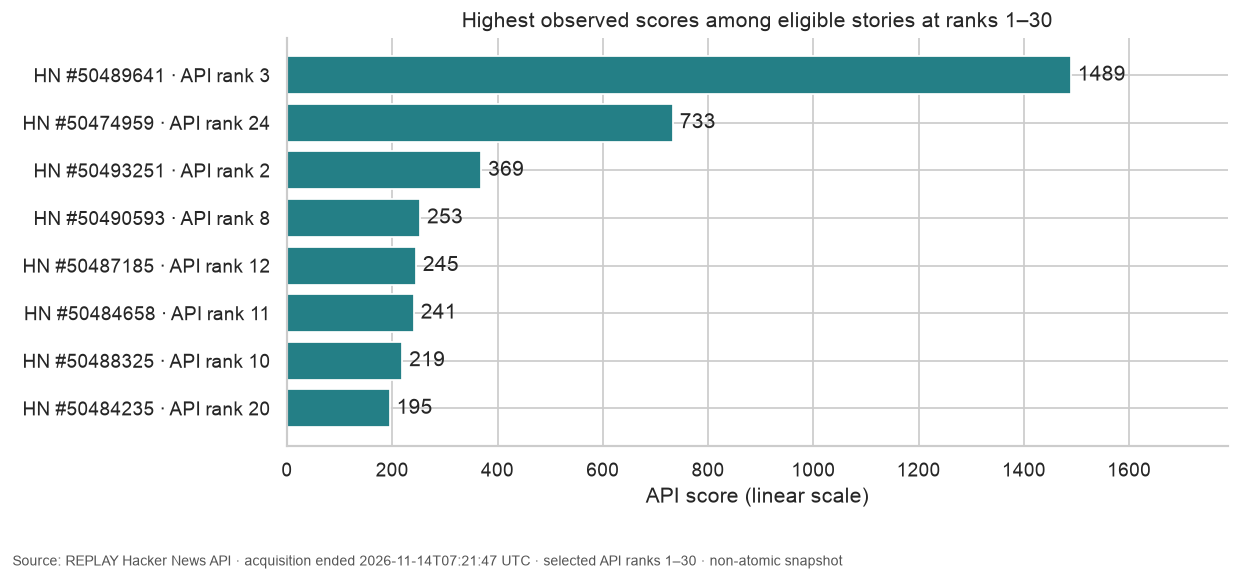

In [13]:
display(leaders)
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = [f"HN #{row.id} · API rank {row.rank}" for row in leaders.itertuples()]
bars = ax.barh(labels, leaders.score, color="#247f86")
ax.bar_label(bars, padding=4, fmt="%.0f")
ax.invert_yaxis()
ax.set(
    xlabel="API score (linear scale)",
    title=f"Highest observed scores among eligible stories at ranks 1–{TOP_N}",
    xlim=(0, max(1, leaders.score.max() * 1.2)),
)
finish(fig)

## Experiment: widen the same ranking prefix

Change only `TOP_N` from **30 to 100** and run a separate copy. Compare eligibility counts, the number of comparable pairs, disagreement fraction and the eight highest scores. More eligible items create more pairs, but the fraction may rise or fall. The source fingerprint and replay request count must stay unchanged. Restore **30** afterwards.

This comparison changes the included population. It cannot isolate age, moderation, score changes during hydration or other ranking inputs. A time series would need repeated snapshots with documented clocks and stable identifiers; this notebook records one ranking response followed by item responses.

In [14]:
con.close()
if server:
    server.close()
if previous_base is None:
    os.environ.pop("HN_BASE_URL", None)
else:
    os.environ["HN_BASE_URL"] = previous_base

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)